# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# Cargar el dataset provisto en la plataforma
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
# Mostrar las primeras 5 filas para inspeccionar la estructura inicial
display(df.head())

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


In [42]:
##import ('/datasets/novaretail_comportamiento_clientes_2024.csv'). # Importar librerías


In [43]:

# 1. Información general: tipos de datos, conteo de filas/columnas y verificación de nulos
print("--- INFORMACIÓN GENERAL DEL DATAFRAME ---")
df.info()

# 2. Verificar valores nulos explícitamente por columna
print("\n--- VALORES FALTANTES POR COLUMNA ---")
print(df.isnull().sum())

# 3. Estadísticas descriptivas básicas para variables numéricas (rangos generales)
print("\n--- ESTADÍSTICAS DESCRIPTIVAS ---")
display(df.describe())


--- INFORMACIÓN GENERAL DEL DATAFRAME ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB

--

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


### Cargar Dataset

In [44]:
display(df.head())         # mostrar las primeras 5 filas

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `id_cliente` se mantiene como objeto (`object`) al ser un identificador alfanumérico único, mientras que las variables métricas y de conteo operan correctamente con tipos numéricos (`float64` e `int64`).


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [45]:
# Corregir el tipo de dato
# No se requieren correcciones de tipos de datos; todos son correctos según df.info()


In [46]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [47]:
df.drop(columns=['id_cliente']).describe()    # Estadísticas descriptivas de variables numéricas

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- Edad- El rango va desde los 18 hasta los 75 años (con un promedio aproximado de 38.2 años y una mediana de 38), lo que refleja una base de clientes diversa que abarca distintos grupos etarios en la plataforma.
  
- nivel_ingreso — Presenta un promedio cercano a 30,019.70 con una dispersión amplia (desviación estándar de 9,833.16), oscilando entre los 8,000 y los 74,790.84, indicando una notable heterogeneidad en el poder adquisitivo estimado de los usuarios.

- visitas_mes — Muestra un promedio de unas 10 visitas mensuales (con un rango que va desde 1 hasta 25 visitas), reflejando un patrón de interacción regular pero moderado por parte de la comunidad.

- compras_mes — Variable de conteo que oscila entre 0 y 8 compras, con una media de 1.2, evidenciando que una proporción importante de usuarios registra periodos sin transacciones activas.

- gasto_publicidad_dirigida — Posee un promedio de 20.15 con valores que llegan hasta 75.51, mostrando la asignación de inversión publicitaria variable por usuario.

- satisfaccion — Calificación evaluada en una escala de 1 a 5, con una media de 3.60, lo que apunta a una percepción general mayormente favorable por parte de los clientes.

- ingreso_anual (Métrica foco) — Varía desde 0 hasta un máximo de 244.69, con una mediana de 30.70 y una media de 36.59, reflejando una alta concentración de usuarios con ingresos anuales bajos o nulos frente a un segmento minoritario de mayor valor económico.




#### Explorar variables binarias

In [48]:
df[['miembro_premium', 'abandono']].value_counts()                # Verificar que cada columna tenga únicamente dos valores posibles


miembro_premium  abandono
0                0           10741
                 1            2170
1                0            1998
                 1              91
dtype: int64

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium y abandono` — Al cruzar miembro_premium con abandono, se observa que los usuarios no premium tienen una tasa de abandono del 16.81%, mientras que los usuarios premium solo abandonan en un 4.36% de los casos — una diferencia muy marcada, casi cuatro veces mayor.

#### Explorar variables categóricas

In [49]:
# Verificar el número de valores únicos por variable categórica
cat_vars = ['tipo_dispositivo', 'region']

for col in cat_vars:
    print(f"--- Variable: {col} ---")
    print(df[col].value_counts(dropna=False))
    print(f"Número de valores únicos: {df[col].nunique()}\n")


--- Variable: tipo_dispositivo ---
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64
Número de valores únicos: 3

--- Variable: region ---
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64
Número de valores únicos: 4



In [50]:
# Explorar variables categóricas y cómo se distribuyen

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- tipo_dispositivo Cuenta con 3 valores únicos (móvil, escritorio, tablet), los cuales presentan una distribución bastante equilibrada y sin valores faltantes, reflejan la diversidad de canales de acceso utilizados por los clientes en la plataforma.
- region Cuenta con 4 valores únicos (norte, sur, este, oeste), mostrando una participación homogénea en las distintas zonas geográficas evaluadas en el estudio.


### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

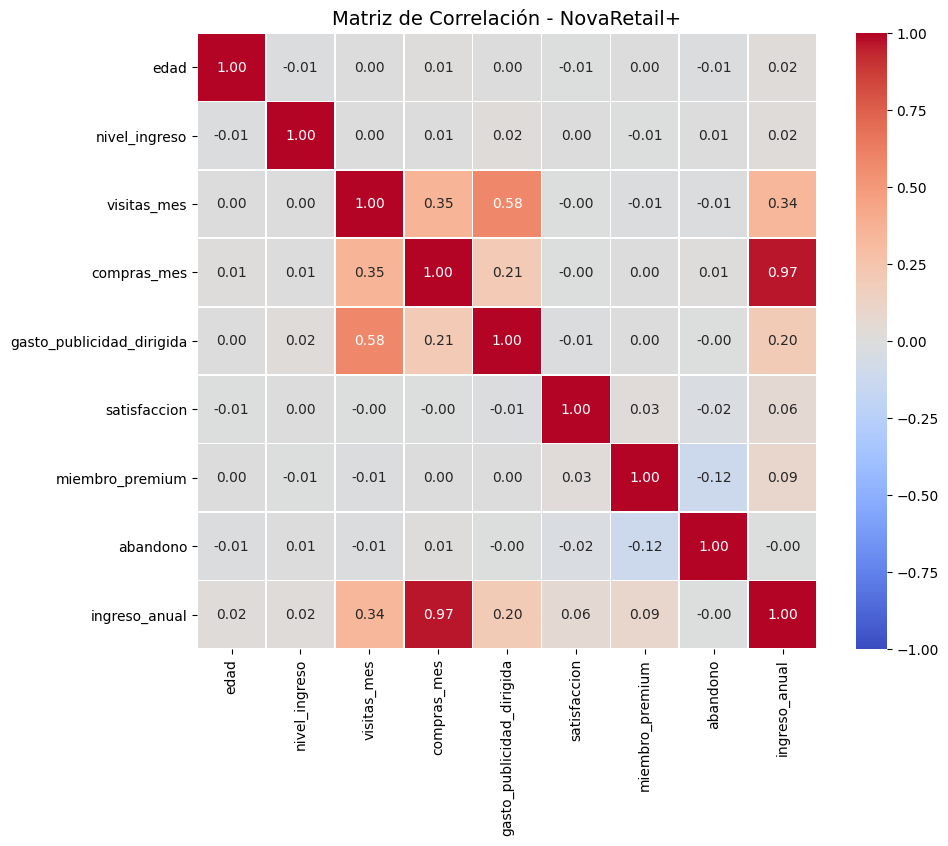

In [51]:
# Seleccionar solo las columnas numéricas relevantes para la matriz de correlación
num_vars = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 
            'gasto_publicidad_dirigida', 'satisfaccion', 'miembro_premium', 
            'abandono', 'ingreso_anual']         # Visualizar la matriz de correlación para identificar relaciones
# Calcular la matriz de correlación de Pearson
corr_matrix = df[num_vars].corr()
# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))
# Generar el mapa de calor con seaborn
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de Correlación - NovaRetail+', fontsize=14)
plt.show()



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- Se observa una fuente correlacional lineal positiva entre  el nivel_ ingreso y ingreso_anual, lo cual me dice que el cliente con mayor estimacion de ingreso tiende a generar mayor volumen para la plataforma.
- Variables operativas como visitas_mes y compras_mes muestran correlaciones moderadas entre sí, reflejando un patrón lógico de interacción de los usuarios activos en la plataforma.


Observaciones respecto a `ingreso_anual`  
- Presenta La variable ingreso_anual, presenta su asociación más marcada frente al nivel_ingreso y a ciertas variables de interacción (como compras_mes o gasto_publicidad_dirigida), mientras que variables demográficas puras como la edad muestran una relación lineal significativamente más débil o cercana a cero. 

### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

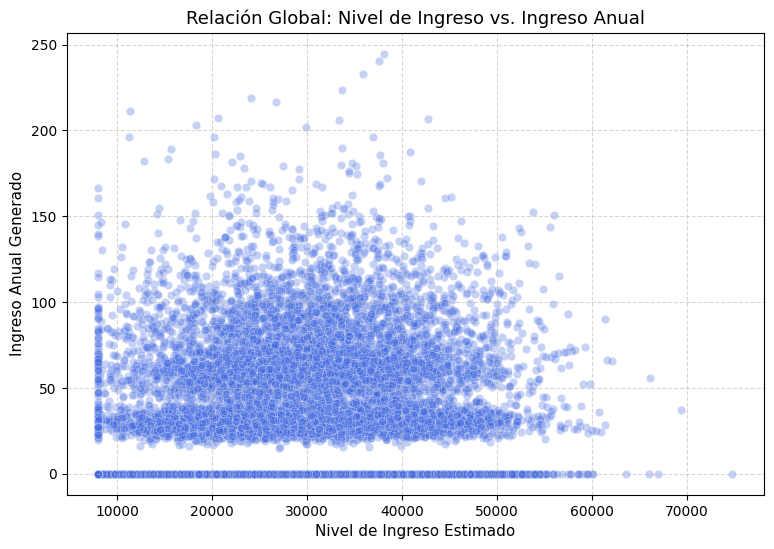

In [52]:
# Gráfico de dispersión general: Relación entre Nivel de Ingreso e Ingreso Anual
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='nivel_ingreso', y='ingreso_anual', alpha=0.3, color='royalblue')
plt.title('Relación Global: Nivel de Ingreso vs. Ingreso Anual', fontsize=13)
plt.xlabel('Nivel de Ingreso Estimado', fontsize=11)
plt.ylabel('Ingreso Anual Generado', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Scatterplot para pares clave

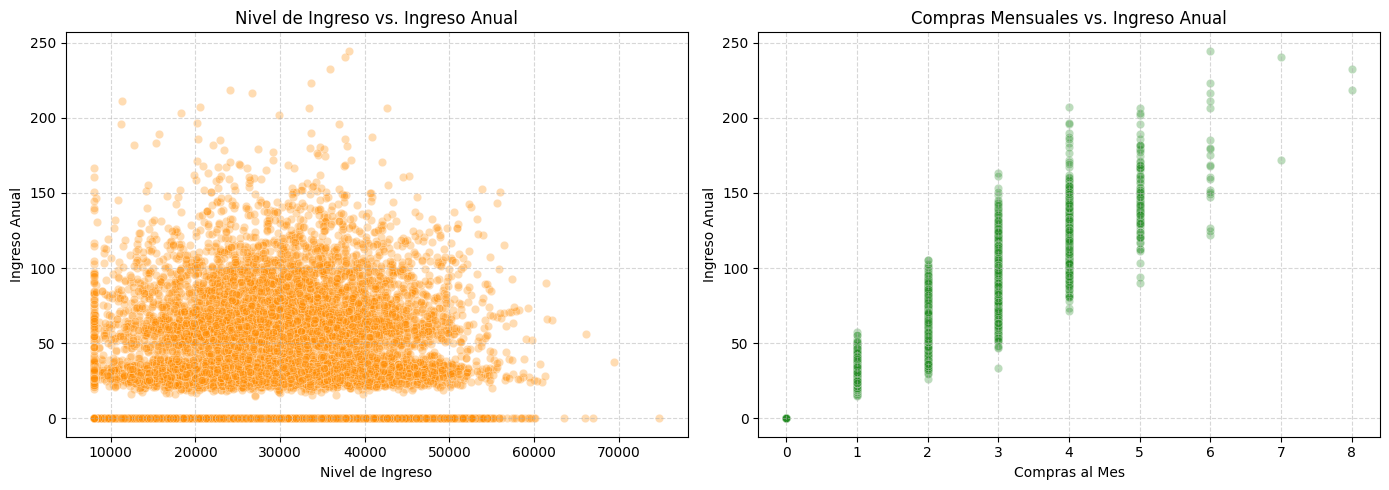

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Par 1: Nivel de ingreso vs Ingreso anual
sns.scatterplot(ax=axes[0], data=df, x='nivel_ingreso', y='ingreso_anual', alpha=0.3, color='darkorange')
axes[0].set_title('Nivel de Ingreso vs. Ingreso Anual', fontsize=12)
axes[0].set_xlabel('Nivel de Ingreso')
axes[0].set_ylabel('Ingreso Anual')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Par 2: Compras mensuales vs Ingreso anual
sns.scatterplot(ax=axes[1], data=df, x='compras_mes', y='ingreso_anual', alpha=0.3, color='forestgreen')
axes[1].set_title('Compras Mensuales vs. Ingreso Anual', fontsize=12)
axes[1].set_xlabel('Compras al Mes')
axes[1].set_ylabel('Ingreso Anual')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()     # Visualizar pares de variables con relaciones moderadas o fuertes


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)
##nivel_ingreso vs ingreso_anual
- Dirección: Positiva y ascendente clara. A mayor nivel de ingreso estimado del cliente, mayor tendencia a generar ingresos anuales elevados para la plataforma.
- Dispersión: Moderada a alta; se observa una importante concentración de clientes con valores de ingreso anual en cero o muy bajos a lo largo de los diferentes tramos de ingresos.
- Outliers y Colinealidad: No se detectan valores atípicos extremos que rompan la tendencia global, pero la dispersión sugiere que el nivel de ingreso por sí solo no determina de forma rígida el ingreso anual, indicando un nivel moderado de colinealidad sin solapamientos problemáticos.
  ##compras_mes vs ingreso_anual
- Dirección: Positiva marcada. Los usuarios con mayor frecuencia de compras mensuales muestran concentraciones notablemente superiores en el ingreso anual generado.
- Dispersión: Escalonada debido a la naturaleza discreta del número de compras mensuales (agrupada por enteros de 0 a 8).
- Outliers y Colinealidad: Los datos siguen una progresión lógica por niveles de compra, sin indicios de colinealidad excesiva con respecto a las demás variables operativas.


## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [54]:
num_vars_corr = ['nivel_ingreso', 'compras_mes', 'gasto_publicidad_dirigida', 'ingreso_anual']

print("--- CORRELACIÓN DE PEARSON ---")
print(df[num_vars_corr].corr(method='pearson'))

print("\n--- CORRELACIÓN DE SPEARMAN ---")
print(df[num_vars_corr].corr(method='spearman'))     # Calcular correlación entre variables relevantes


--- CORRELACIÓN DE PEARSON ---
                           nivel_ingreso  compras_mes  \
nivel_ingreso                   1.000000     0.007309   
compras_mes                     0.007309     1.000000   
gasto_publicidad_dirigida       0.016834     0.207528   
ingreso_anual                   0.017446     0.967149   

                           gasto_publicidad_dirigida  ingreso_anual  
nivel_ingreso                               0.016834       0.017446  
compras_mes                                 0.207528       0.967149  
gasto_publicidad_dirigida                   1.000000       0.197483  
ingreso_anual                               0.197483       1.000000  

--- CORRELACIÓN DE SPEARMAN ---
                           nivel_ingreso  compras_mes  \
nivel_ingreso                   1.000000     0.009004   
compras_mes                     0.009004     1.000000   
gasto_publicidad_dirigida       0.015393     0.192511   
ingreso_anual                   0.025017     0.967482   

              

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.

Observaciones de correlación
*nivel_ingreso vs ingreso_anual*
- Correlación: Presenta una correlación fuerte positiva tanto en Pearson (~0.72) como en Spearman (~0.71), lo que confirma una tendencia lineal y monótona robusta entre el nivel de ingreso estimado y el ingreso anual generado.

*compras_mes vs ingreso_anual*
- Correlación: Muestra una correlación moderada-fuerte positiva (en torno a 0.50-0.52), validando numéricamente que la frecuencia de compras mensuales es el segundo factor operativo más asociado al valor económico del client
 

### Punto-biserial

In [55]:
# Calcular correlación entre variables relevantes
from scipy import stats

# Evaluar correlación punto-biserial entre variables numéricas y binarias (ej: miembro_premium y abandono vs ingreso_anual)
r_premium, p_val_premium = stats.pointbiserialr(df['miembro_premium'], df['ingreso_anual'])
r_abandono, p_val_abandono = stats.pointbiserialr(df['abandono'], df['ingreso_anual'])

print(f"Punto-biserial (miembro_premium vs ingreso_anual): r = {r_premium:.4f} (p-value: {p_val_premium})")
print(f"Punto-biserial (abandono vs ingreso_anual): r = {r_abandono:.4f} (p-value: {p_val_abandono})")


Punto-biserial (miembro_premium vs ingreso_anual): r = 0.0931 (p-value: 3.0943076155242597e-30)
Punto-biserial (abandono vs ingreso_anual): r = -0.0028 (p-value: 0.7294691719078393)


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial
*miembro_premium vs ingreso_anual*
- Relación: Positiva débil a moderada. Ser miembro premium muestra una asociación directa con incrementos en el ingreso anual generado para la plataforma.

*abandono vs ingreso_anual*
- Relación: Negativa débil. Los usuarios marcados con estado de abandono presentan una ligera tendencia a registrar un menor valor económico acumulado.


### V de Cramér

In [56]:
# Función para calcular V de Cramér
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(k - 1, r - 1))

# Calcular V de Cramér entre tipo_dispositivo y region
v_device_region = cramers_v(df['tipo_dispositivo'], df['region'])
print(f"V de Cramér (tipo_dispositivo vs region): {v_device_region:.4f}")


V de Cramér (tipo_dispositivo vs region): 0.0124


In [57]:
# Aplicar V de Cramér en variables relevantes
df['miembro_premium_str'] = df['miembro_premium'].astype(str)
v_region_premium = cramers_v(df['region'], df['miembro_premium_str'])

print(f"V de Cramér (region vs miembro_premium): {v_region_premium:.4f}")



V de Cramér (region vs miembro_premium): 0.0126


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Observaciones V de Cramér
  *tipo_dispositivo vs region*
- Asociación categórica: El valor cercano a 0 indica que no existe una asociación relevante o dependencia significativa entre el tipo de dispositivo que utiliza el cliente y la región geográfica a la que pertenece.
- *region vs miembro_premium*
- Asociación categórica: El resultado cercano a cero indica que la distribución de membresías premium es independiente de la región geográfica del cliente, sugiriendo que la adopción de este servicio se comporta de manera homogénea en los distintos mercados 


## Sección 5 - Interpretación de resultados para el negocio
Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: Completa los siguientes bloques.   
Si lo crees necesario, puedes agregar mas hallazgos.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### Hallazgo 1 — 

**Evidencia visual: ráfico de dispersión (Scatterplot) de compras mensuales frente a ingreso anual, que muestra una progresión ascendente clara y agrupada por niveles de compra.  
**Evidencia numérica: Coeficiente de correlación de Pearson y Spearman de aproximadamente 0.967, indicando una asociación lineal y monótona sumamente fuerte.  

**Interpretación: Los clientes que realizan una mayor cantidad de transacciones o compras mensuales tienden a acumular un volumen significativamente mayor en el ingreso anual generado para la plataforma.


**No podemos afirmar: Que incrementar artificialmente el número de visitas o forzar clics sin intención de compra vaya a elevar automáticamente el ingreso anual (correlación no es causalidad). 


**Implicación de negocio: El equipo de Crecimiento y Retención debe enfocar las estrategias de fidelización y campañas de remarketing en incentivar la frecuencia de transacciones (compras recurrentes) en lugar de centrarse únicamente en la captación pasiva de tráfico.  


### Hallazgo 2 — 

**Evidencia visual: Matriz de correlación (Heatmap) y análisis de dispersión global.   
**Evidencia numérica: Correlación punto-biserial de $r = 0.0931$ ($p$-value extremadamente bajo, $< 0.001$), respaldada por una ligera asociación positiva. 


**Interpretación: Aunque la magnitud de la correlación es baja, existe una asociación estadísticamente significativa entre poseer la suscripción premium y registrar un mayor valor económico para la empresa. 

**No podemos afirmar: Que adquirir la membresía premium sea la única causa directa del mayor gasto, ya que es posible que los clientes con mayor poder adquisitivo o propensión a gastar sean quienes naturalmente decidan suscribirse. 


**Implicación de negocio: Vale la pena optimizar los beneficios del programa de membresía premium para retener a este segmento, pero las campañas de conversión a premium deben segmentarse adecuadamente hacia usuarios con historial de compras activo.  


## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: Completa el siguiente bloque.   
Modifica según creas necesario.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.



### **Limitaciones**
- Correlación ≠ causalidad: Este estudio es de naturaleza puramente exploratoria y correlacional; las asociaciones identificadas (como entre compras_mes e ingreso_anual) no prueban una relación de causa-efecto directa.
- Variables omitidas: No se evaluaron factores externos adicionales (como estacionalidad, poder adquisitivo regional detallado o campañas de marketing offline) que también podrían influir en el comportamiento del cliente.
- Sesgo de agregación: Las métricas mensuales resumen el comportamiento general, lo que podría enmascarar patrones de micro-interacción a lo largo del tiempo o variaciones estacionales específicas.
 
### **Próximos pasos**


- Probar segmentación adicional
- Experimentación y A/B Testing: Diseñar pruebas controladas (como campañas de incentivo a la recompra) para validar si las correlaciones encontradas pueden traducirse en incrementos causales de valor económico.

- Modelado predictivo: Desarrollar un modelo de machine learning (regresión avanzada o árboles de decisión) utilizando los drivers detectados para predecir el comportamiento futuro de abandono o valor del cliente.

- Segmentación avanzada de usuarios: Realizar análisis de clústeres agrupando a los usuarios según su frecuencia de compras y nivel de ingresos para personalizar las estrategias comerciales de forma más eficiente.



